In [1]:
from bs4 import BeautifulSoup

In [35]:
def scraping_page(soup, data): 
    quotes = soup.find_all("div", class_="quote")
    for quote in quotes:
        text = quote.find("span", class_="text").text
        author = quote.find("small", class_="author").text
        tags = [
            tag.text 
            for tag in quote.find_all("a", class_="tag")]
        
        data.append({
            "author":author,
            "text": text,
            "tags": tags
        })
    return data

In [15]:
def find_next(soup): 
    next_button = soup.find("li", class_ = "next")
    if next_button: 
        next_link = next_button.find("a")["href"]
        return "https://quotes.toscrape.com"+next_link
    return None

In [36]:
url = "https://quotes.toscrape.com/"
def scraping_pages(url): 
    data = []
    while url: 
        response = requests.get(url)
        soup = BeautifulSoup(response.text,"html.parser")
        scraping_page(soup,data)
        url = find_next(soup)
    return data

In [37]:
quotes_data = scraping_pages(url)

In [38]:
import pandas as pd 
df = pd.DataFrame(quotes_data)
df.to_csv("quotes.csv", index = False)

In [39]:
df.head()

,author,text,tags
0,Albert Einstein,“The world as we have created it is a process ...,"[change, deep-thoughts, thinking, world]"
1,J.K. Rowling,"“It is our choices, Harry, that show what we t...","[abilities, choices]"
2,Albert Einstein,“There are only two ways to live your life. On...,"[inspirational, life, live, miracle, miracles]"
3,Jane Austen,"“The person, be it gentleman or lady, who has ...","[aliteracy, books, classic, humor]"
4,Marilyn Monroe,"“Imperfection is beauty, madness is genius and...","[be-yourself, inspirational]"


In [29]:
df.shape[0]

10

In [40]:
import matplotlib.pyplot as plt

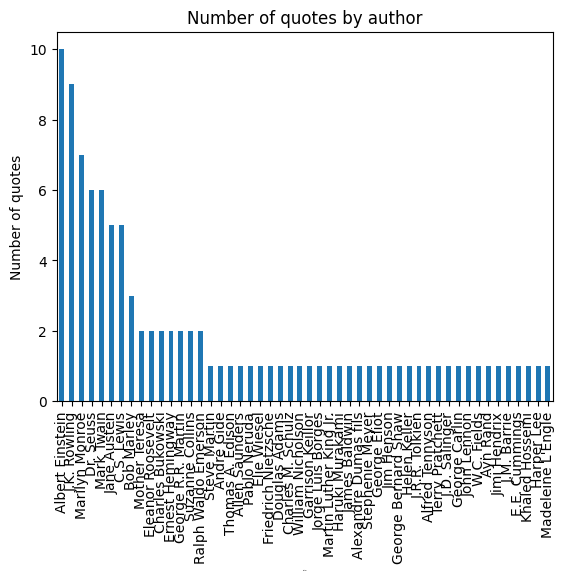

In [46]:
author_count = df["author"].value_counts()

author_count.plot(kind="bar")

plt.xlabel("Author", fontsize = 1)
plt.ylabel("Number of quotes")
plt.title("Number of quotes by author")

plt.show()

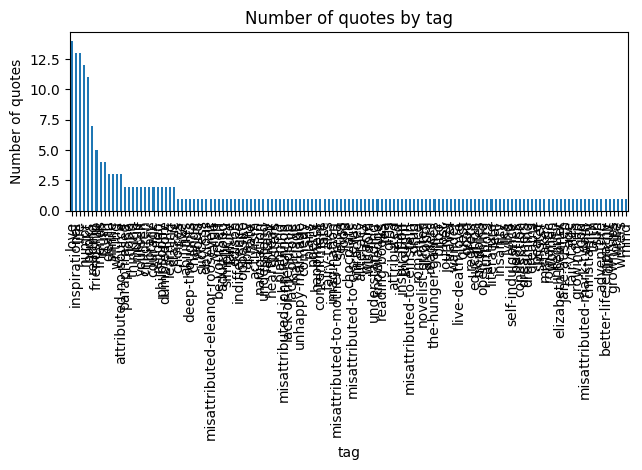

In [55]:
tag_count = df["tags"].explode().value_counts()
tag_count.plot(kind = "bar")

plt.xlabel("tag")
plt.ylabel("Number of quotes")
plt.title("Number of quotes by tag")
plt.tight_layout()
plt.show()

In [52]:
print(tag_count)

tags
love             14
inspirational    13
life             13
humor            12
books            11
                 ..
difficult         1
grown-ups         1
write             1
writers           1
mind              1
Name: count, Length: 137, dtype: int64
